# ECE501 — Digital Image Processing
## Week 6: Investigation and Improvement of Hough Transform

### Project
Vehicle Orientation Estimation Using Conventional Image Processing

### Objective

Week 5 analysis showed that Hough Transform produced a mean angular
error of approximately 12.46°, with some individual predictions
showing errors greater than 80°.

The objective of Week 6 is to investigate the causes of these
large errors and evaluate a modified Hough line-selection method.

### Tasks

1. Recover the 100 vehicle crops from the DRASHTI dataset.
2. Visualise Hough line detection on high-error vehicles.
3. Implement improved line filtering and orientation grouping.
4. Tune the modified method using a training subset.
5. Compare baseline and modified Hough performance.
6. Analyse class-wise errors and individual improvements.
7. Save all experimental results.

Install libraries

In [1]:
!pip -q install remotezip opencv-python-headless seaborn scikit-learn

Mount Google Drive and create folders

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os
import re
import io
import json
import zipfile
import requests

from pathlib import Path
from collections import defaultdict
from itertools import product

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from remotezip import RemoteZip
from sklearn.model_selection import train_test_split
from IPython.display import display

BASE_DIR = Path("/content/drive/MyDrive/ECE501_DRASHTI")

WEEK3_CSV = (
    BASE_DIR / "Week3_Results" /
    "week3_100_image_error_table.csv"
)

ANNOTATION_ZIP = BASE_DIR / "train_original.zip"

WEEK6_DIR = BASE_DIR / "Week6_Results"

CROP_DIR = WEEK6_DIR / "vehicle_crops"
GRAPH_DIR = WEEK6_DIR / "graphs"
TABLE_DIR = WEEK6_DIR / "tables"
VISUAL_DIR = WEEK6_DIR / "visualizations"

for folder in [
    CROP_DIR,
    GRAPH_DIR,
    TABLE_DIR,
    VISUAL_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR)
print("Week 3 CSV exists:", WEEK3_CSV.exists())
print("Annotation ZIP exists:", ANNOTATION_ZIP.exists())

Mounted at /content/drive
Project folder: /content/drive/MyDrive/ECE501_DRASHTI
Week 3 CSV exists: True
Annotation ZIP exists: True


Load Week 3 results

In [3]:
df = pd.read_csv(WEEK3_CSV)

print("Total vehicles:", len(df))
print("\nColumns:")
print(df.columns.tolist())

required_columns = [
    "Vehicle_ID",
    "Vehicle_Class",
    "Ground_Truth_Orientation_deg",
    "Hough_Estimated_Orientation_deg"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

df["Vehicle_ID"] = df["Vehicle_ID"].astype(str)

if df["Vehicle_ID"].duplicated().any():
    raise ValueError("Duplicate Vehicle_ID values found.")

for col in [
    "Ground_Truth_Orientation_deg",
    "Hough_Estimated_Orientation_deg"
]:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df["Historical_Hough_Error_deg"] = abs(
    df["Ground_Truth_Orientation_deg"]
    - df["Hough_Estimated_Orientation_deg"]
)

display(df.head())

print("\nHistorical Hough mean error:")
print(df["Historical_Hough_Error_deg"].mean())

print("\nHistorical Hough median error:")
print(df["Historical_Hough_Error_deg"].median())

Total vehicles: 100

Columns:
['Vehicle_ID', 'Image_ID', 'Vehicle_Number', 'Class_ID', 'Vehicle_Class', 'Difficulty', 'Ground_Truth_Heading_deg', 'Ground_Truth_Orientation_deg', 'PCA_Estimated_Orientation_deg', 'PCA_Angular_Error_deg', 'Hough_Estimated_Orientation_deg', 'Hough_Angular_Error_deg', 'Contour_Estimated_Orientation_deg', 'Contour_Angular_Error_deg']


,Vehicle_ID,Image_ID,Vehicle_Number,Class_ID,Vehicle_Class,Difficulty,Ground_Truth_Heading_deg,Ground_Truth_Orientation_deg,PCA_Estimated_Orientation_deg,PCA_Angular_Error_deg,Hough_Estimated_Orientation_deg,Hough_Angular_Error_deg,Contour_Estimated_Orientation_deg,Contour_Angular_Error_deg,Historical_Hough_Error_deg
0,KNyT_zacV_LpYg_vehicle_1,KNyT_zacV_LpYg,1,5,MotorCycle,0,283.20,76.80,72.51,4.29,82.44,5.64,86.31,9.51,5.64
1,IwEd_XCYw_iwrB_vehicle_1,IwEd_XCYw_iwrB,1,0,Auto3WCargo,0,214.74,34.74,5.61,29.13,54.72,19.98,0.00,34.74,19.98
2,C2g2_vYbb_ihYH_vehicle_1,C2g2_vYbb_ihYH,1,7,SUV,0,239.58,59.58,50.14,9.44,69.57,9.99,52.43,7.15,9.99
3,gqbe_NCQI_MTLw_vehicle_1,gqbe_NCQI_MTLw,1,7,SUV,0,171.34,8.66,0.84,7.82,10.04,1.38,0.00,8.66,1.38
4,boDi_WlMN_s88Y_vehicle_1,boDi_WlMN_s88Y,1,9,Tanker,0,97.00,83.00,83.19,0.19,86.27,3.27,90.00,7.00,3.27



Historical Hough mean error:
12.464897959183673

Historical Hough median error:
4.18


Connect to Zenodo dataset

In [4]:
RECORD_ID = "18278989"

api_url = f"https://zenodo.org/api/records/{RECORD_ID}"

response = requests.get(
    api_url,
    timeout=60
)

response.raise_for_status()

record = response.json()

train_file = next(
    (
        item for item in record["files"]
        if item["key"] == "train.zip"
    ),
    None
)

if train_file is None:
    raise FileNotFoundError(
        "train.zip not found in the Zenodo record."
    )

TRAIN_ZIP_URL = train_file["links"]["self"]

print("Dataset archive:", train_file["key"])

print(
    "Archive size:",
    round(train_file["size"] / (1024 ** 3), 2),
    "GB"
)

print("Remote ZIP URL obtained successfully.")

Dataset archive: train.zip
Archive size: 6.97 GB
Remote ZIP URL obtained successfully.


Open the ZIP remotely

In [5]:
print("Connecting to remote train.zip...")

try:
    remote_zip = RemoteZip(
        TRAIN_ZIP_URL,
        timeout=120
    )

    remote_files = remote_zip.namelist()

    print("Connection successful!")
    print("Total archive entries:", len(remote_files))

    print("\nFirst 20 entries:")

    for filename in remote_files[:20]:
        print(filename)

except Exception as e:
    raise RuntimeError(
        "Could not access train.zip using HTTP range requests. "
        "The server may not support remote ZIP access. "
        f"Original error: {e}"
    )

Connecting to remote train.zip...
Connection successful!
Total archive entries: 16571

First 20 entries:
train/008s_Z0OT_vtne.jpg
train/00KF_8PHt_jJ8M.jpg
train/00sq_cBbT_X84h.jpg
train/00XD_3rEO_4KVW.jpg
train/01AM_E3Lm_fKAO.jpg
train/01Bv_6OpA_c89J.jpg
train/01hA_C6z3_VdN8.jpg
train/01LJ_fZb4_oClj.jpg
train/02Ct_4Npq_OCfR.jpg
train/02G5_pZHE_M78G.jpg
train/02ti_N3Lj_OUTw.jpg
train/031E_UOzB_kHLb.jpg
train/031y_3S3N_tJ7e.jpg
train/037b_wWCs_KEnU.jpg
train/03aT_pyHq_0iPv.jpg
train/03He_Lytl_97GH.jpg
train/03Je_8NB5_rq28.jpg
train/03LL_AqBg_TubE.jpg
train/03mA_ofP0_hnDf.jpg
train/04bI_3IHT_fok0.jpg


Match Week 3 vehicle IDs to source images

In [6]:
def split_vehicle_id(vehicle_id):

    match = re.fullmatch(
        r"(.+)_vehicle_(\d+)",
        str(vehicle_id)
    )

    if match is None:
        raise ValueError(
            f"Invalid Vehicle_ID: {vehicle_id}"
        )

    return match.group(1), int(match.group(2))


df["Source_Image_ID"] = df["Vehicle_ID"].apply(
    lambda x: split_vehicle_id(x)[0]
)

required_image_ids = set(
    df["Source_Image_ID"]
)

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
)

image_lookup = defaultdict(list)

for filename in remote_files:

    if filename.lower().endswith(IMAGE_EXTENSIONS):

        image_id = Path(filename).stem

        if image_id in required_image_ids:
            image_lookup[image_id].append(filename)


print("Required unique source images:",
      len(required_image_ids))

print("Matched source images:",
      len(image_lookup))

missing_images = (
    required_image_ids - set(image_lookup)
)

print("Missing source images:",
      len(missing_images))

print("\nFirst 10 matches:")

for image_id, paths in list(image_lookup.items())[:10]:
    print(image_id, "->", paths)

if missing_images:
    print("\nExamples of missing image IDs:")
    print(sorted(missing_images)[:10])

Required unique source images: 100
Matched source images: 100
Missing source images: 0

First 10 matches:
00XD_3rEO_4KVW -> ['train/00XD_3rEO_4KVW.jpg']
2GuW_AKSD_y8m2 -> ['train/2GuW_AKSD_y8m2.jpg']
2h07_apct_WjnB -> ['train/2h07_apct_WjnB.jpg']
3J2E_oL5U_TE2G -> ['train/3J2E_oL5U_TE2G.jpg']
3LzM_y7ht_SdIz -> ['train/3LzM_y7ht_SdIz.jpg']
4AYY_W6bt_vwi6 -> ['train/4AYY_W6bt_vwi6.jpg']
5N3r_jiDF_1pzt -> ['train/5N3r_jiDF_1pzt.jpg']
5QtK_2GHz_wRDq -> ['train/5QtK_2GHz_wRDq.jpg']
6fBl_Ztbw_EnVh -> ['train/6fBl_Ztbw_EnVh.jpg']
6JBU_iCb9_Lszd -> ['train/6JBU_iCb9_Lszd.jpg']


## 1. Vehicle Crop Reconstruction

The original Week 3 experiment evaluated 100 vehicle samples,
but the individual vehicle crops were not saved.

The crops are therefore reconstructed using the original
DRASHTI dataset images and corresponding annotations.

The vehicle IDs from Week 3 are used to locate the original
aerial frames.

The annotation files provide oriented bounding-box coordinates
for identifying each vehicle region.

The bounding boxes are used only for extracting vehicle crops.
Their orientations are not used for predicting vehicle direction.

Read annotations and load images

In [7]:
annotation_zip = zipfile.ZipFile(
    ANNOTATION_ZIP,
    "r"
)

annotation_lookup = {}

for filename in annotation_zip.namelist():

    if filename.lower().endswith(".txt"):

        image_id = Path(filename).stem

        annotation_lookup[image_id] = filename


def read_annotations(image_id):

    if image_id not in annotation_lookup:
        raise FileNotFoundError(
            f"Annotation missing: {image_id}"
        )

    content = annotation_zip.read(
        annotation_lookup[image_id]
    ).decode("utf-8-sig")

    lines = [
        line.strip()
        for line in content.splitlines()
        if line.strip()
    ]

    return lines


def load_source_image(image_id):

    matches = image_lookup.get(image_id, [])

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one source image for {image_id}, "
            f"found {len(matches)}"
        )

    image_bytes = remote_zip.read(
        matches[0]
    )

    image_array = np.frombuffer(
        image_bytes,
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise ValueError(
            f"Could not decode image: {image_id}"
        )

    return image


print("Annotation files indexed:",
      len(annotation_lookup))

Annotation files indexed: 16571


Inspect one image and annotation

Sample image ID: 00XD_3rEO_4KVW
Image shape: (2160, 3840, 3)

First 5 annotation lines:
Line 0: flightHeight:62.43
Line 1: 713 820 844 970 912 911 781 761 SUV 0 49.0
Line 2: 200 705 442 691 437 598 195 612 Sedan 0 356.66
Line 3: 746 1048 644 1056 647 1101 749 1093 MotorCycle 0 175.42
Line 4: 1419 502 1515 502 1515 460 1419 460 MotorCycle 0 0.0


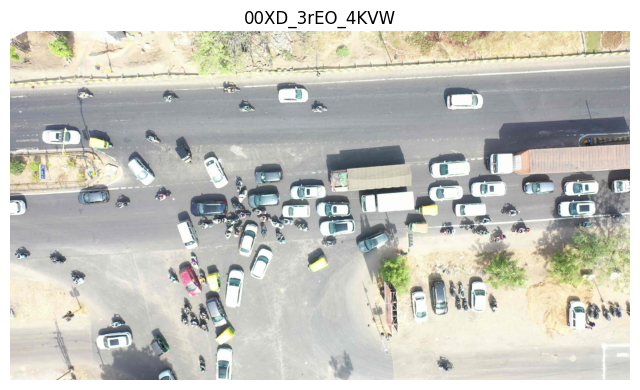

In [8]:
available_ids = [
    image_id
    for image_id in sorted(required_image_ids)
    if len(image_lookup.get(image_id, [])) == 1
    and image_id in annotation_lookup
]

if not available_ids:
    raise ValueError(
        "No image IDs match both the remote images "
        "and the local annotation ZIP."
    )

sample_id = available_ids[0]

sample_image = load_source_image(sample_id)
sample_annotations = read_annotations(sample_id)

print("Sample image ID:", sample_id)
print("Image shape:", sample_image.shape)

print("\nFirst 5 annotation lines:")

for i, line in enumerate(sample_annotations[:5]):
    print(f"Line {i}: {line}")

plt.figure(figsize=(8, 8))

plt.imshow(
    cv2.cvtColor(
        sample_image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(sample_id)
plt.axis("off")
plt.show()

Parse annotation records

In [9]:
def parse_vehicle_annotations(image_id):

    lines = read_annotations(image_id)

    records = []

    # Skip the first line (flight-height metadata).
    vehicle_lines = lines[1:]

    for vehicle_number, line in enumerate(
        vehicle_lines,
        start=1
    ):

        parts = line.split()

        if len(parts) < 11:
            raise ValueError(
                f"Unexpected annotation format: "
                f"{image_id}, line {vehicle_number}"
            )

        corners = np.array(
            [float(x) for x in parts[:8]],
            dtype=np.float32
        ).reshape(4, 2)

        records.append({
            "Vehicle_Number": vehicle_number,
            "Corners": corners,
            "Vehicle_Class": parts[8],
            "Difficulty": parts[9],
            "Heading_deg": float(parts[10])
        })

    return records


sample_records = parse_vehicle_annotations(
    sample_id
)

print("Number of annotated vehicles:",
      len(sample_records))

print("\nFirst vehicle annotation:")

print(sample_records[0])

Number of annotated vehicles: 104

First vehicle annotation:
{'Vehicle_Number': 1, 'Corners': array([[713., 820.],
       [844., 970.],
       [912., 911.],
       [781., 761.]], dtype=float32), 'Vehicle_Class': 'SUV', 'Difficulty': '0', 'Heading_deg': 49.0}


Extract and save the 100 vehicle crops

In [10]:
def extract_vehicle_crop(
    image,
    corners,
    padding=5
):

    height, width = image.shape[:2]

    x_min = max(
        0,
        int(np.floor(corners[:, 0].min())) - padding
    )

    y_min = max(
        0,
        int(np.floor(corners[:, 1].min())) - padding
    )

    x_max = min(
        width,
        int(np.ceil(corners[:, 0].max())) + padding
    )

    y_max = min(
        height,
        int(np.ceil(corners[:, 1].max())) + padding
    )

    if x_max <= x_min or y_max <= y_min:
        raise ValueError(
            "Invalid bounding-box coordinates."
        )

    return image[
        y_min:y_max,
        x_min:x_max
    ].copy()


crop_records = []
extraction_failures = []

for image_id, group in df.groupby(
    "Source_Image_ID"
):

    try:
        image = load_source_image(image_id)

        annotations = parse_vehicle_annotations(
            image_id
        )

    except Exception as e:

        for vehicle_id in group["Vehicle_ID"]:

            extraction_failures.append({
                "Vehicle_ID": vehicle_id,
                "Reason": str(e)
            })

        continue

    for _, row in group.iterrows():

        vehicle_id = row["Vehicle_ID"]

        try:

            _, vehicle_number = split_vehicle_id(
                vehicle_id
            )

            if not (
                1 <= vehicle_number <= len(annotations)
            ):
                raise IndexError(
                    "Vehicle number outside annotation range."
                )

            annotation = annotations[
                vehicle_number - 1
            ]

            # Check that the annotation class matches
            # the class recorded in Week 3.

            csv_class = str(
                row["Vehicle_Class"]
            ).strip().lower()

            annotation_class = str(
                annotation["Vehicle_Class"]
            ).strip().lower()

            if csv_class != annotation_class:
                raise ValueError(
                    f"Class mismatch: "
                    f"{csv_class} vs {annotation_class}"
                )

            crop = extract_vehicle_crop(
                image,
                annotation["Corners"],
                padding=5
            )

            crop_path = (
                CROP_DIR /
                f"{vehicle_id}.jpg"
            )

            if not cv2.imwrite(
                str(crop_path),
                crop
            ):
                raise IOError(
                    "Failed to save vehicle crop."
                )

            crop_records.append({
                "Vehicle_ID": vehicle_id,
                "Crop_Path": str(crop_path),
                "Annotation_Heading_deg":
                    annotation["Heading_deg"],
                "Crop_Width": crop.shape[1],
                "Crop_Height": crop.shape[0]
            })

        except Exception as e:

            extraction_failures.append({
                "Vehicle_ID": vehicle_id,
                "Reason": str(e)
            })


crop_manifest = pd.DataFrame(
    crop_records,
    columns=[
        "Vehicle_ID",
        "Crop_Path",
        "Annotation_Heading_deg",
        "Crop_Width",
        "Crop_Height"
    ]
)

failure_table = pd.DataFrame(
    extraction_failures,
    columns=[
        "Vehicle_ID",
        "Reason"
    ]
)

crop_manifest.to_csv(
    TABLE_DIR / "01_vehicle_crop_manifest.csv",
    index=False
)

failure_table.to_csv(
    TABLE_DIR / "02_extraction_failures.csv",
    index=False
)

print("Successfully extracted:",
      len(crop_manifest))

print("Failed:",
      len(failure_table))

if len(failure_table):
    display(failure_table.head(10))

Successfully extracted: 99
Failed: 1


,Vehicle_ID,Reason
0,nnOQ_5C6s_y5jd_vehicle_1,500 Server Error: INTERNAL SERVER ERROR for ur...


In [11]:
import time
import cv2

failed_vehicle_id = "nnOQ_5C6s_y5jd_vehicle_1"

image_id, vehicle_number = split_vehicle_id(failed_vehicle_id)

crop_path = CROP_DIR / f"{failed_vehicle_id}.jpg"

for attempt in range(1, 6):

    try:
        print(f"Attempt {attempt}/5...")

        # Retrieve only the required source image
        image = load_source_image(image_id)

        # Read its annotations
        annotations = parse_vehicle_annotations(image_id)

        annotation = annotations[vehicle_number - 1]

        # Validate the vehicle class
        expected_class = str(
            df.loc[
                df["Vehicle_ID"] == failed_vehicle_id,
                "Vehicle_Class"
            ].iloc[0]
        ).strip().lower()

        actual_class = str(
            annotation["Vehicle_Class"]
        ).strip().lower()

        if expected_class != actual_class:
            raise ValueError(
                f"Class mismatch: {expected_class} vs {actual_class}"
            )

        # Extract the vehicle
        crop = extract_vehicle_crop(
            image,
            annotation["Corners"],
            padding=5
        )

        if not cv2.imwrite(str(crop_path), crop):
            raise IOError("Could not save crop")

        print("✅ Vehicle successfully recovered!")
        print("Saved:", crop_path)

        break

    except Exception as e:

        print("Error:", str(e))

        if attempt < 5:
            wait = 5 * attempt
            print(f"Retrying in {wait} seconds...")
            time.sleep(wait)

else:
    print("❌ Unable to recover this vehicle after 5 attempts.")

Attempt 1/5...
✅ Vehicle successfully recovered!
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week6_Results/vehicle_crops/nnOQ_5C6s_y5jd_vehicle_1.jpg


In [12]:
available = 0
missing = []

for vehicle_id in df["Vehicle_ID"]:

    path = CROP_DIR / f"{vehicle_id}.jpg"

    if path.exists():
        available += 1
    else:
        missing.append(vehicle_id)

print("Available crops:", available)
print("Missing crops:", len(missing))

if missing:
    print("Missing vehicle IDs:", missing)

Available crops: 100
Missing crops: 0


In [13]:
if crop_path.exists():

    recovered_record = pd.DataFrame([{
        "Vehicle_ID": failed_vehicle_id,
        "Crop_Path": str(crop_path),
        "Annotation_Heading_deg": annotation["Heading_deg"],
        "Crop_Width": crop.shape[1],
        "Crop_Height": crop.shape[0]
    }])

    crop_manifest = pd.concat(
        [crop_manifest, recovered_record],
        ignore_index=True
    )

    crop_manifest = crop_manifest.drop_duplicates(
        subset=["Vehicle_ID"],
        keep="last"
    )

    crop_manifest.to_csv(
        TABLE_DIR / "01_vehicle_crop_manifest.csv",
        index=False
    )

    print("Updated manifest:", len(crop_manifest))

Updated manifest: 100


Validate and display crops

Available crops: 100


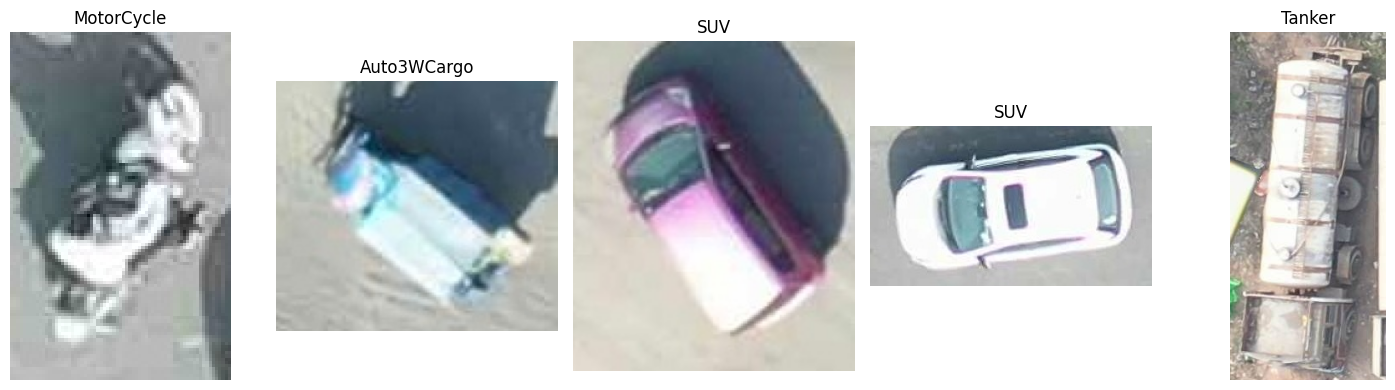

In [15]:
df = df.merge(
    crop_manifest,
    on="Vehicle_ID",
    how="left",
    validate="one_to_one"
)

print("Available crops:",
      df["Crop_Path"].notna().sum())

# Validate heading correspondence when
# the original heading column is available.

if "Ground_Truth_Heading_deg" in df.columns:

    original_heading = pd.to_numeric(
        df["Ground_Truth_Heading_deg"],
        errors="coerce"
    )

    annotation_heading = df[
        "Annotation_Heading_deg"
    ]

    difference = abs(
        (
            original_heading
            - annotation_heading
            + 180
        ) % 360 - 180
    )

    if (difference > 0.1).any():
        raise ValueError(
            "Annotation headings do not match "
            "the Week 3 records."
        )


sample_crops = df.dropna(
    subset=["Crop_Path"]
).head(5)

if len(sample_crops) == 0:
    raise ValueError(
        "No crops were recovered."
    )

fig, axes = plt.subplots(
    1,
    len(sample_crops),
    figsize=(15, 4)
)

axes = np.atleast_1d(axes)

for ax, (_, row) in zip(
    axes,
    sample_crops.iterrows()
):

    image = cv2.imread(
        row["Crop_Path"]
    )

    ax.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    ax.set_title(
        row["Vehicle_Class"]
    )

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "01_reconstructed_crops.png",
    dpi=300
)

plt.show()

## 2. Hough Transform Analysis

The reconstructed vehicle crops are processed using
conventional image-processing operations.

The preprocessing steps include:

1. Grayscale conversion
2. Contrast enhancement using CLAHE
3. Gaussian smoothing
4. Canny edge detection
5. Morphological closing

The Probabilistic Hough Transform is then used to detect
line segments.

The baseline method combines detected line orientations
using a length-weighted axial mean.

The modified method filters short segments and selects
the dominant orientation group before estimating the
vehicle's orientation.

Preprocessing and Hough functions

In [16]:
def preprocess_vehicle(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    blurred = cv2.GaussianBlur(
        enhanced,
        (5, 5),
        0
    )

    edges = cv2.Canny(
        blurred,
        50,
        150
    )

    kernel = np.ones(
        (3, 3),
        np.uint8
    )

    edges = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel
    )

    return edges


def detect_hough_lines(
    edges,
    threshold=30,
    min_line_length=20,
    max_line_gap=10
):

    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=threshold,
        minLineLength=min_line_length,
        maxLineGap=max_line_gap
    )

    if lines is None:
        return np.empty(
            (0, 4),
            dtype=np.int32
        )

    return lines.reshape(-1, 4)


def get_line_properties(lines):

    if len(lines) == 0:
        return np.array([]), np.array([])

    dx = lines[:, 2] - lines[:, 0]
    dy = lines[:, 3] - lines[:, 1]

    lengths = np.hypot(dx, dy)

    angles = (
        np.degrees(
            np.arctan2(dy, dx)
        ) % 180
    )

    return angles, lengths


def axial_mean(angles, weights):

    if len(angles) == 0:
        return np.nan

    doubled_angles = np.deg2rad(
        2 * angles
    )

    x = np.sum(
        weights * np.cos(doubled_angles)
    )

    y = np.sum(
        weights * np.sin(doubled_angles)
    )

    if np.hypot(x, y) < 1e-10:
        return np.nan

    return (
        np.degrees(
            np.arctan2(y, x)
        ) / 2
    ) % 180


def fold_orientation(axis):

    if not np.isfinite(axis):
        return np.nan

    axis = axis % 180

    return min(
        axis,
        180 - axis
    )

Baseline Hough

In [17]:
def baseline_hough(image):

    edges = preprocess_vehicle(image)

    lines = detect_hough_lines(
        edges
    )

    angles, lengths = get_line_properties(
        lines
    )

    axis = axial_mean(
        angles,
        lengths
    )

    orientation = fold_orientation(
        axis
    )

    return (
        orientation,
        axis,
        lines,
        edges
    )

Modified Hough

In [18]:
def modified_hough(
    image,
    threshold=30,
    min_line_length=20,
    max_line_gap=10,
    min_relative_length=0.08,
    bin_width=15
):

    edges = preprocess_vehicle(image)

    lines = detect_hough_lines(
        edges,
        threshold=threshold,
        min_line_length=min_line_length,
        max_line_gap=max_line_gap
    )

    angles, lengths = get_line_properties(
        lines
    )

    if len(lines) == 0:
        return (
            np.nan,
            np.nan,
            lines,
            lines,
            edges
        )

    height, width = image.shape[:2]

    min_length = (
        min_relative_length
        * np.hypot(height, width)
    )

    valid = lengths >= min_length

    filtered_lines = lines[valid]
    filtered_angles = angles[valid]
    filtered_lengths = lengths[valid]

    if len(filtered_lines) == 0:
        return (
            np.nan,
            np.nan,
            lines,
            filtered_lines,
            edges
        )

    centers = np.arange(
        0,
        180,
        bin_width
    )

    scores = []

    for center in centers:

        distance = np.abs(
            (
                filtered_angles
                - center
                + 90
            ) % 180 - 90
        )

        selected = (
            distance <= bin_width / 2
        )

        scores.append(
            filtered_lengths[selected].sum()
        )

    best_center = centers[
        np.argmax(scores)
    ]

    distance = np.abs(
        (
            filtered_angles
            - best_center
            + 90
        ) % 180 - 90
    )

    selected = (
        distance <= bin_width / 2
    )

    selected_lines = filtered_lines[
        selected
    ]

    axis = axial_mean(
        filtered_angles[selected],
        filtered_lengths[selected]
    )

    orientation = fold_orientation(
        axis
    )

    return (
        orientation,
        axis,
        lines,
        selected_lines,
        edges
    )

## 3. Visual Analysis of High-Error Vehicles

The five vehicles with the largest angular errors in the
original Week 3 Hough experiment are selected for inspection.

For each vehicle, four images are generated:

1. Original vehicle crop
2. Preprocessed edge map
3. All detected Hough lines
4. Selected lines from the modified method

This analysis helps investigate whether inaccurate predictions
are associated with incorrect line selection, background edges,
vehicle structures, or ambiguous vehicle geometry.

Visualise worst five vehicles

Five highest-error available vehicles:


,Vehicle_ID,Vehicle_Class,Historical_Hough_Error_deg
84,cLEH_vQvJ_zAUO_vehicle_1,Trailer,82.39
72,hwun_OlDq_ey5G_vehicle_1,Auto3WCargo,81.49
19,dH2R_2Thg_72eh_vehicle_1,SUV,79.96
74,wmtT_f6a4_vb0t_vehicle_1,SUV,79.39
49,y0bo_oHBY_y2mz_vehicle_1,Container,77.16


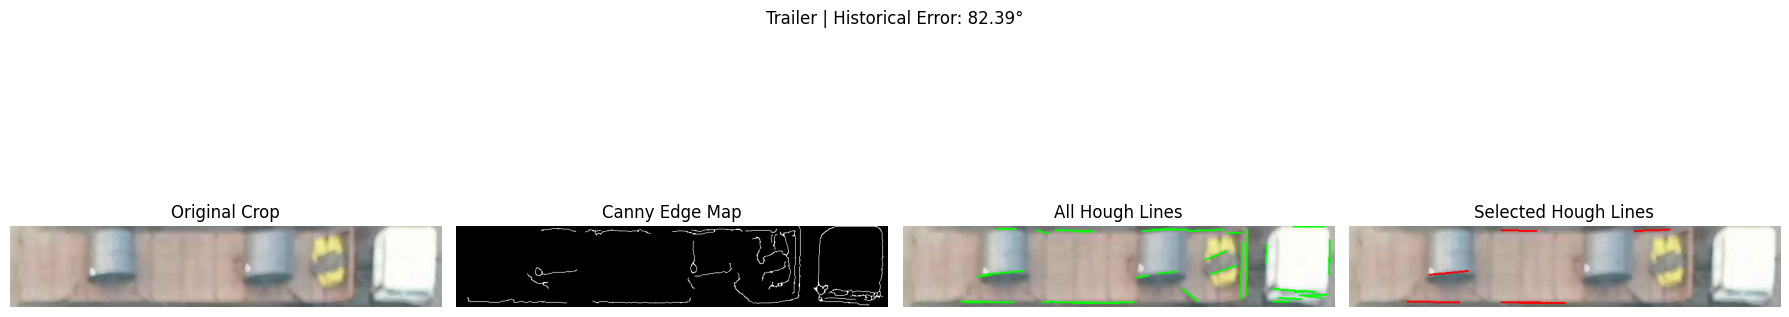

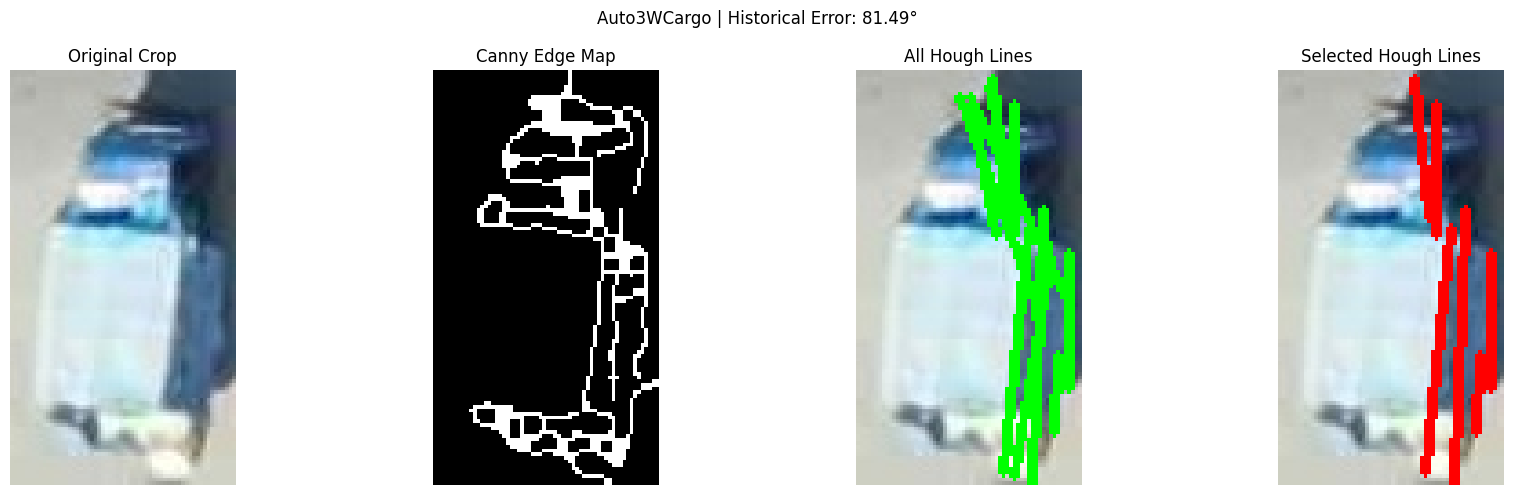

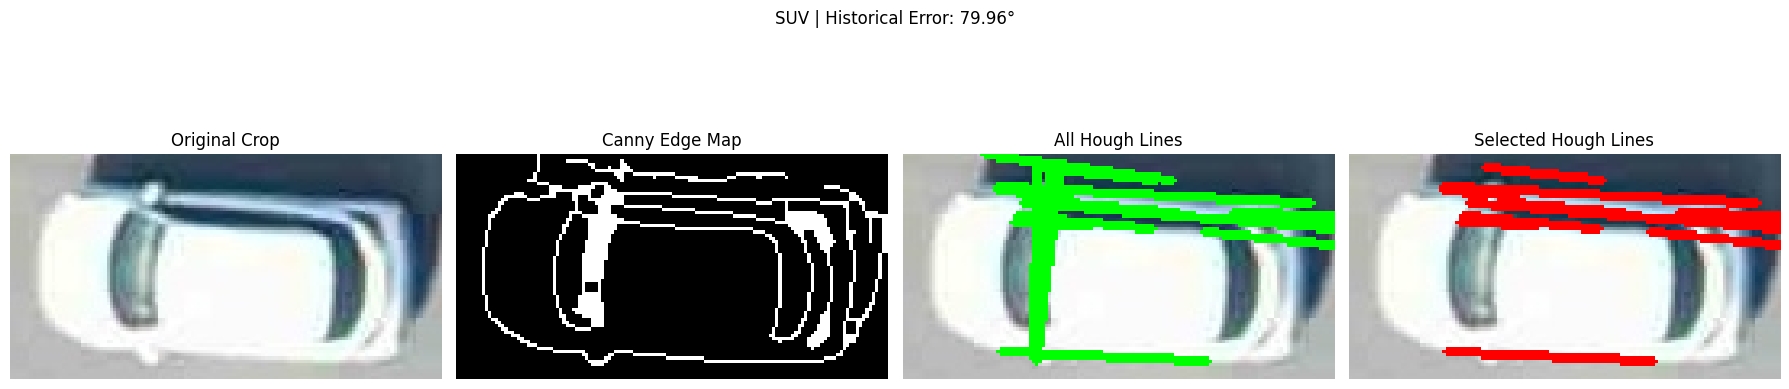

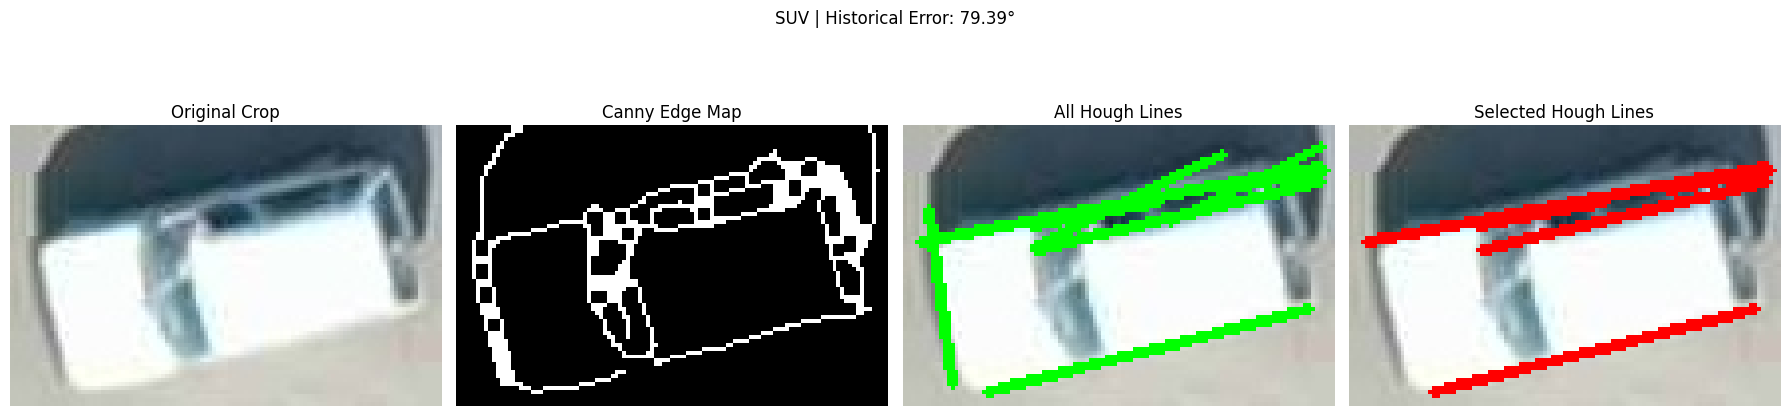

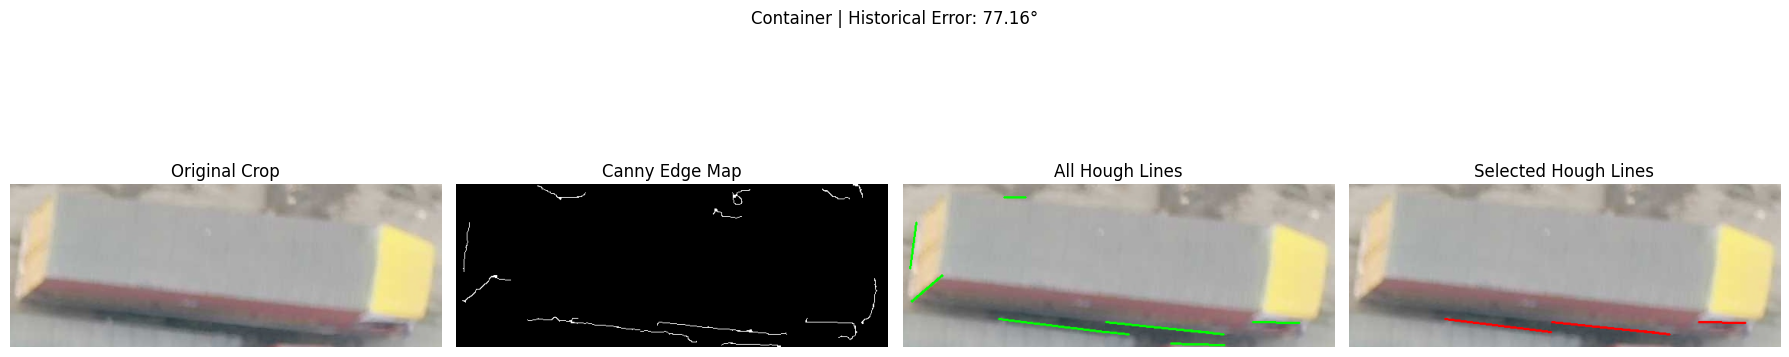

In [19]:
def draw_lines(
    image,
    lines,
    color=(0, 255, 0)
):

    output = image.copy()

    for x1, y1, x2, y2 in lines:

        cv2.line(
            output,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            color,
            2
        )

    return output


worst5 = (
    df.dropna(
        subset=[
            "Historical_Hough_Error_deg",
            "Crop_Path"
        ]
    )
    .sort_values(
        "Historical_Hough_Error_deg",
        ascending=False
    )
    .head(5)
)

print("Five highest-error available vehicles:")

display(
    worst5[
        [
            "Vehicle_ID",
            "Vehicle_Class",
            "Historical_Hough_Error_deg"
        ]
    ]
)

for _, row in worst5.iterrows():

    image = cv2.imread(
        row["Crop_Path"]
    )

    (
        modified_pred,
        modified_axis,
        all_lines,
        selected_lines,
        edges
    ) = modified_hough(image)

    all_overlay = draw_lines(
        image,
        all_lines
    )

    selected_overlay = draw_lines(
        image,
        selected_lines,
        color=(0, 0, 255)
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(18, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[0].set_title("Original Crop")

    axes[1].imshow(
        edges,
        cmap="gray"
    )
    axes[1].set_title("Canny Edge Map")

    axes[2].imshow(
        cv2.cvtColor(
            all_overlay,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[2].set_title("All Hough Lines")

    axes[3].imshow(
        cv2.cvtColor(
            selected_overlay,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[3].set_title("Selected Hough Lines")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{row['Vehicle_Class']} | "
        f"Historical Error: "
        f"{row['Historical_Hough_Error_deg']:.2f}°"
    )

    plt.tight_layout()

    plt.savefig(
        VISUAL_DIR /
        f"{row['Vehicle_ID']}_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 4. Modified Hough Evaluation

The modified method is evaluated using separate tuning
and held-out subsets.

Parameter selection is performed using the tuning subset.

The held-out subset is used to evaluate the final selected
parameters without further adjustment.

The comparison includes:

- Historical Hough results
- Recomputed baseline Hough results
- Modified Hough results

Evaluation metrics include mean angular error, median
angular error, maximum error, prediction failures,
and class-wise performance.

Split dataset

In [20]:
experiment_df = (
    df.dropna(
        subset=[
            "Crop_Path",
            "Ground_Truth_Orientation_deg"
        ]
    )
    .sort_values("Vehicle_ID")
    .copy()
    .reset_index(drop=True)
)

if len(experiment_df) < 10:
    raise ValueError(
        "Insufficient recovered vehicle crops."
    )

source_ids = experiment_df[
    "Source_Image_ID"
].unique()

if len(source_ids) < 2:
    raise ValueError(
        "Need at least two source images "
        "for an image-grouped split."
    )

train_sources, test_sources = train_test_split(
    source_ids,
    test_size=0.30,
    random_state=42
)

experiment_df["Split"] = np.where(
    experiment_df["Source_Image_ID"].isin(
        train_sources
    ),
    "Tuning",
    "Held-out"
)

print(experiment_df["Split"].value_counts())

experiment_df.to_csv(
    TABLE_DIR / "03_experiment_split.csv",
    index=False
)

Split
Tuning      70
Held-out    30
Name: count, dtype: int64


Parameter tuning

In [21]:
image_cache = {}

for _, row in experiment_df.iterrows():

    image_cache[row["Vehicle_ID"]] = cv2.imread(
        row["Crop_Path"]
    )


parameter_grid = list(
    product(
        [20, 30, 40],
        [15, 25],
        [5, 10],
        [0.05, 0.10],
        [10, 20]
    )
)


def evaluate_parameters(
    data,
    params
):

    (
        threshold,
        min_length,
        max_gap,
        relative_length,
        bin_width
    ) = params

    errors = []
    failures = 0

    for _, row in data.iterrows():

        image = image_cache[
            row["Vehicle_ID"]
        ]

        pred, _, _, _, _ = modified_hough(
            image,
            threshold=threshold,
            min_line_length=min_length,
            max_line_gap=max_gap,
            min_relative_length=relative_length,
            bin_width=bin_width
        )

        if not np.isfinite(pred):
            failures += 1

        else:
            errors.append(
                abs(
                    row["Ground_Truth_Orientation_deg"]
                    - pred
                )
            )

    score = (
        sum(errors)
        + 90 * failures
    ) / len(data)

    return score, failures


tuning_df = experiment_df[
    experiment_df["Split"] == "Tuning"
]

tuning_results = []

for params in parameter_grid:

    score, failures = evaluate_parameters(
        tuning_df,
        params
    )

    tuning_results.append({
        "Threshold": params[0],
        "Min_Line_Length": params[1],
        "Max_Line_Gap": params[2],
        "Min_Relative_Length": params[3],
        "Bin_Width": params[4],
        "Selection_Score": score,
        "Failures": failures
    })


tuning_results = pd.DataFrame(
    tuning_results
).sort_values(
    "Selection_Score"
)

tuning_results.to_csv(
    TABLE_DIR / "04_parameter_tuning.csv",
    index=False
)

display(tuning_results.head(10))

best = tuning_results.iloc[0]

BEST_PARAMS = {
    "threshold": int(best["Threshold"]),
    "min_line_length": int(
        best["Min_Line_Length"]
    ),
    "max_line_gap": int(
        best["Max_Line_Gap"]
    ),
    "min_relative_length": float(
        best["Min_Relative_Length"]
    ),
    "bin_width": int(
        best["Bin_Width"]
    )
}

print("Selected parameters:")
print(BEST_PARAMS)

,Threshold,Min_Line_Length,Max_Line_Gap,Min_Relative_Length,Bin_Width,Selection_Score,Failures
17,30,15,5,0.05,20,3.871446,0
41,40,25,5,0.05,20,4.716006,0
19,30,15,5,0.10,20,5.157677,0
25,30,25,5,0.05,20,5.600507,0
37,40,15,10,0.05,20,5.622374,0
39,40,15,10,0.10,20,5.634852,0
47,40,25,10,0.10,20,5.805225,0
45,40,25,10,0.05,20,5.806429,0
21,30,15,10,0.05,20,6.114164,0
33,40,15,5,0.05,20,6.317785,0


Selected parameters:
{'threshold': 30, 'min_line_length': 15, 'max_line_gap': 5, 'min_relative_length': 0.05, 'bin_width': 20}


Run both methods

In [22]:
results = []

for _, row in experiment_df.iterrows():

    image = image_cache[
        row["Vehicle_ID"]
    ]

    (
        baseline_pred,
        baseline_axis,
        baseline_lines,
        _
    ) = baseline_hough(image)

    (
        modified_pred,
        modified_axis,
        all_lines,
        selected_lines,
        _
    ) = modified_hough(
        image,
        **BEST_PARAMS
    )

    gt = row[
        "Ground_Truth_Orientation_deg"
    ]

    baseline_error = (
        abs(gt - baseline_pred)
        if np.isfinite(baseline_pred)
        else np.nan
    )

    modified_error = (
        abs(gt - modified_pred)
        if np.isfinite(modified_pred)
        else np.nan
    )

    results.append({
        "Vehicle_ID": row["Vehicle_ID"],
        "Vehicle_Class": row["Vehicle_Class"],
        "Split": row["Split"],

        "Ground_Truth_Orientation_deg": gt,

        "Historical_Hough_Error_deg":
            row["Historical_Hough_Error_deg"],

        "Baseline_Orientation_deg":
            baseline_pred,

        "Baseline_Axis_deg":
            baseline_axis,

        "Baseline_Error_deg":
            baseline_error,

        "Modified_Orientation_deg":
            modified_pred,

        "Modified_Axis_deg":
            modified_axis,

        "Modified_Error_deg":
            modified_error,

        "Detected_Line_Count":
            len(all_lines),

        "Selected_Line_Count":
            len(selected_lines)
    })


results_df = pd.DataFrame(results)

results_df["Improvement_deg"] = (
    results_df["Baseline_Error_deg"]
    - results_df["Modified_Error_deg"]
)

results_df.to_csv(
    TABLE_DIR / "05_hough_results.csv",
    index=False
)

display(results_df.head())

,Vehicle_ID,Vehicle_Class,Split,Ground_Truth_Orientation_deg,Historical_Hough_Error_deg,Baseline_Orientation_deg,Baseline_Axis_deg,Baseline_Error_deg,Modified_Orientation_deg,Modified_Axis_deg,Modified_Error_deg,Detected_Line_Count,Selected_Line_Count,Improvement_deg
0,00XD_3rEO_4KVW_vehicle_1,SUV,Held-out,49.00,3.86,49.173872,49.173872,0.173872,46.306921,46.306921,2.693079,82,30,-2.519207
1,2GuW_AKSD_y8m2_vehicle_1,MotorCycle,Tuning,2.36,4.17,3.432828,3.432828,1.072828,1.903204,1.903204,0.456796,31,17,0.616032
2,2h07_apct_WjnB_vehicle_1,SUV,Tuning,11.62,19.45,13.887047,166.112953,2.267047,12.251209,167.748791,0.631209,11,7,1.635838
3,3J2E_oL5U_TE2G_vehicle_1,SUV,Tuning,4.66,4.25,1.814374,1.814374,2.845626,0.617572,0.617572,4.042428,28,23,-1.196802
4,3LzM_y7ht_SdIz_vehicle_1,SUV,Held-out,24.90,2.56,42.125512,137.874488,17.225512,26.649071,26.649071,1.749071,86,15,15.476441


**Graphs and Results**

Overall comparison

In [23]:
def summarise_method(
    data,
    column,
    method
):

    errors = data[column].dropna()

    return {
        "Method": method,
        "Total_Vehicles": len(data),
        "Successful": len(errors),
        "Failed": len(data) - len(errors),
        "Mean_Error_deg": errors.mean(),
        "Median_Error_deg": errors.median(),
        "Maximum_Error_deg": errors.max(),
        "Std_Error_deg": errors.std()
    }


summary_rows = []

methods = {
    "Historical Week 3 Hough":
        "Historical_Hough_Error_deg",

    "Week 6 Baseline Hough":
        "Baseline_Error_deg",

    "Week 6 Modified Hough":
        "Modified_Error_deg"
}

for split_name in [
    "Tuning",
    "Held-out"
]:

    subset = results_df[
        results_df["Split"] == split_name
    ]

    for method, column in methods.items():

        summary = summarise_method(
            subset,
            column,
            method
        )

        summary["Split"] = split_name

        summary_rows.append(summary)


comparison_df = pd.DataFrame(
    summary_rows
)

comparison_df.to_csv(
    TABLE_DIR / "06_overall_comparison.csv",
    index=False
)

display(comparison_df.round(2))

,Method,Total_Vehicles,Successful,Failed,Mean_Error_deg,Median_Error_deg,Maximum_Error_deg,Std_Error_deg,Split
0,Historical Week 3 Hough,70,68,2,13.35,4.27,82.39,22.11,Tuning
1,Week 6 Baseline Hough,70,70,0,7.79,3.51,81.04,14.55,Tuning
2,Week 6 Modified Hough,70,70,0,3.87,2.02,34.00,5.49,Tuning
3,Historical Week 3 Hough,30,30,0,10.46,3.83,77.16,16.17,Held-out
4,Week 6 Baseline Hough,30,30,0,8.01,4.76,82.68,14.77,Held-out
5,Week 6 Modified Hough,30,30,0,8.81,2.35,84.94,18.24,Held-out


Mean error comparison graph

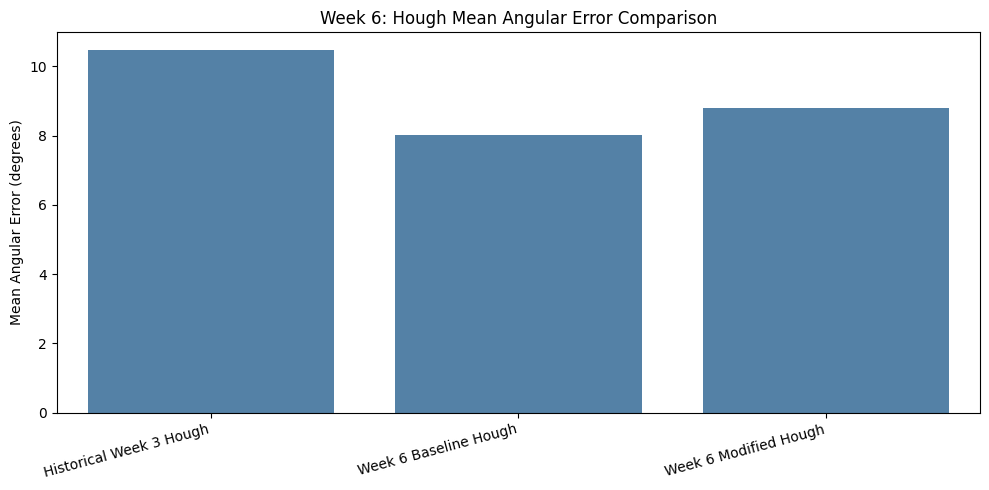

In [24]:
heldout_summary = comparison_df[
    comparison_df["Split"] == "Held-out"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=heldout_summary,
    x="Method",
    y="Mean_Error_deg",
    color="steelblue"
)

plt.title(
    "Week 6: Hough Mean Angular Error Comparison"
)

plt.ylabel(
    "Mean Angular Error (degrees)"
)

plt.xlabel("")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR /
    "01_mean_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Class-wise analysis

,Vehicle_Class,Sample_Count,Baseline_Mean_Error,Modified_Mean_Error,Baseline_Failures,Modified_Failures,Error_Reduction_deg
0,Container,1,4.81,0.49,0,0,4.32
1,MotorCycle,12,4.69,7.51,0,0,-2.82
2,PickUp,2,4.96,3.02,0,0,1.93
3,SUV,11,12.51,9.49,0,0,3.02
4,Sedan,2,6.72,1.05,0,0,5.66
5,Tanker,1,4.00,1.29,0,0,2.71
6,Truck,1,14.16,59.82,0,0,-45.66


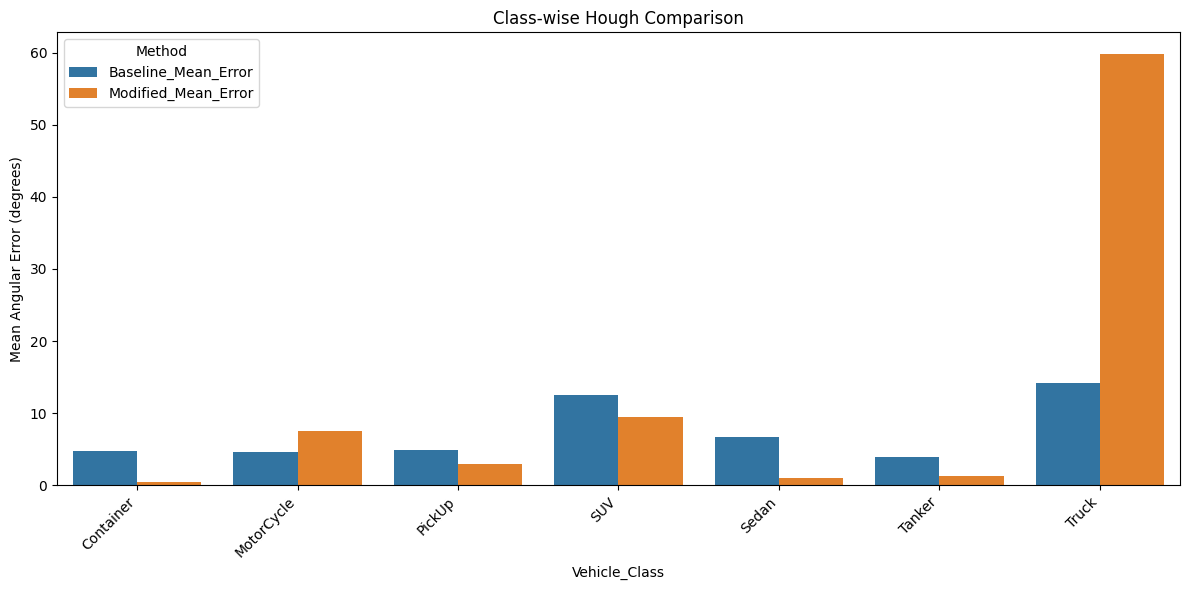

In [25]:
heldout = results_df[
    results_df["Split"] == "Held-out"
].copy()

class_stats = heldout.groupby(
    "Vehicle_Class"
).agg(
    Sample_Count=(
        "Vehicle_ID",
        "count"
    ),

    Baseline_Mean_Error=(
        "Baseline_Error_deg",
        "mean"
    ),

    Modified_Mean_Error=(
        "Modified_Error_deg",
        "mean"
    ),

    Baseline_Failures=(
        "Baseline_Error_deg",
        lambda x: x.isna().sum()
    ),

    Modified_Failures=(
        "Modified_Error_deg",
        lambda x: x.isna().sum()
    )
).reset_index()

class_stats["Error_Reduction_deg"] = (
    class_stats["Baseline_Mean_Error"]
    - class_stats["Modified_Mean_Error"]
)

class_stats.to_csv(
    TABLE_DIR / "07_classwise_comparison.csv",
    index=False
)

display(class_stats.round(2))

plot_df = class_stats.melt(
    id_vars="Vehicle_Class",
    value_vars=[
        "Baseline_Mean_Error",
        "Modified_Mean_Error"
    ],
    var_name="Method",
    value_name="Mean_Error"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Vehicle_Class",
    y="Mean_Error",
    hue="Method"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel(
    "Mean Angular Error (degrees)"
)

plt.title(
    "Class-wise Hough Comparison"
)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR /
    "02_classwise_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Error distribution

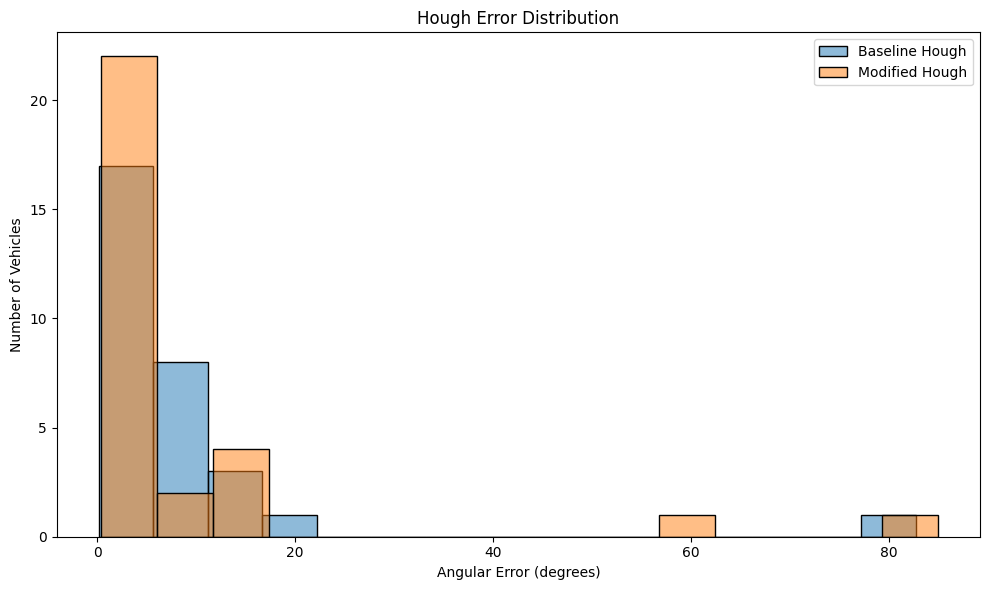

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    heldout["Baseline_Error_deg"].dropna(),
    bins=15,
    alpha=0.5,
    label="Baseline Hough"
)

sns.histplot(
    heldout["Modified_Error_deg"].dropna(),
    bins=15,
    alpha=0.5,
    label="Modified Hough"
)

plt.xlabel(
    "Angular Error (degrees)"
)

plt.ylabel(
    "Number of Vehicles"
)

plt.title(
    "Hough Error Distribution"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    GRAPH_DIR /
    "03_error_distribution.png",
    dpi=300
)

plt.show()

Improvement analysis

In [27]:
paired = heldout.dropna(
    subset=[
        "Baseline_Error_deg",
        "Modified_Error_deg"
    ]
).copy()

improved = paired[
    paired["Improvement_deg"] > 0
]

worsened = paired[
    paired["Improvement_deg"] < 0
]

unchanged = paired[
    paired["Improvement_deg"] == 0
]

print("Improved vehicles:", len(improved))
print("Worsened vehicles:", len(worsened))
print("Unchanged vehicles:", len(unchanged))

print("\nTop improved vehicles:")

display(
    improved.sort_values(
        "Improvement_deg",
        ascending=False
    ).head(10)
)

print("\nTop worsened vehicles:")

display(
    worsened.sort_values(
        "Improvement_deg"
    ).head(10)
)

paired.to_csv(
    TABLE_DIR /
    "08_improvement_analysis.csv",
    index=False
)

Improved vehicles: 18
Worsened vehicles: 12
Unchanged vehicles: 0

Top improved vehicles:


,Vehicle_ID,Vehicle_Class,Split,Ground_Truth_Orientation_deg,Historical_Hough_Error_deg,Baseline_Orientation_deg,Baseline_Axis_deg,Baseline_Error_deg,Modified_Orientation_deg,Modified_Axis_deg,Modified_Error_deg,Detected_Line_Count,Selected_Line_Count,Improvement_deg
4,3LzM_y7ht_SdIz_vehicle_1,SUV,Held-out,24.90,2.56,42.125512,137.874488,17.225512,26.649071,26.649071,1.749071,86,15,15.476441
90,uNXO_Lo8b_u7zl_vehicle_1,SUV,Held-out,0.00,3.22,11.862166,168.137834,11.862166,1.009819,1.009819,1.009819,91,45,10.852347
12,8eh6_NPoT_oEl1_vehicle_1,MotorCycle,Held-out,41.64,9.27,50.436145,50.436145,8.796145,40.598532,40.598532,1.041468,12,4,7.754677
30,MOL9_poaA_17Ap_vehicle_1,Sedan,Held-out,0.00,3.80,7.896664,7.896664,7.896664,1.600330,1.600330,1.600330,24,15,6.296334
45,UejR_B3so_pdhs_vehicle_1,SUV,Held-out,7.46,0.94,15.246325,164.753675,7.786325,5.904717,174.095283,1.555283,41,23,6.231043
31,McY4_xL3v_IDUJ_vehicle_1,PickUp,Held-out,1.76,12.82,10.059480,169.940520,8.299480,4.611493,175.388507,2.851493,42,24,5.447986
39,PjJB_b1vq_Vxav_vehicle_1,SUV,Held-out,9.36,1.26,3.347968,176.652032,6.012032,8.645938,171.354062,0.714062,36,9,5.297969
40,PmvM_uL7n_KIk1_vehicle_1,Sedan,Held-out,0.94,19.86,6.479088,6.479088,5.539088,0.433385,179.566615,0.506615,69,34,5.032473
96,y0bo_oHBY_y2mz_vehicle_1,Container,Held-out,6.00,77.16,1.189737,1.189737,4.810263,5.514727,5.514727,0.485273,14,4,4.324990
76,oTfS_WAxB_x73N_vehicle_1,MotorCycle,Held-out,25.74,12.49,34.164035,145.835965,8.424035,20.512591,159.487409,5.227409,26,17,3.196626



Top worsened vehicles:


,Vehicle_ID,Vehicle_Class,Split,Ground_Truth_Orientation_deg,Historical_Hough_Error_deg,Baseline_Orientation_deg,Baseline_Axis_deg,Baseline_Error_deg,Modified_Orientation_deg,Modified_Axis_deg,Modified_Error_deg,Detected_Line_Count,Selected_Line_Count,Improvement_deg
69,lPCV_CAG5_X9at_vehicle_2,Truck,Held-out,20.00,15.49,5.836005,174.163995,14.163995,79.823794,79.823794,59.823794,83,10,-45.659799
26,KNyT_zacV_LpYg_vehicle_1,MotorCycle,Held-out,76.80,5.64,76.313314,103.686686,0.486686,59.913522,120.086478,16.886478,42,17,-16.399792
9,6TWc_P2qX_R4VI_vehicle_1,MotorCycle,Held-out,2.30,2.60,1.801980,1.801980,0.498020,16.106670,163.893330,13.806670,30,8,-13.308649
83,sEEm_KbEu_D5wV_vehicle_1,MotorCycle,Held-out,1.24,0.72,8.675989,8.675989,7.435989,14.633261,14.633261,13.393261,35,14,-5.957271
80,qWs1_rR7s_qewk_vehicle_1,MotorCycle,Held-out,2.90,1.97,14.518762,14.518762,11.618762,20.093776,20.093776,17.193776,35,22,-5.575013
70,mCA9_HWns_Z2vx_vehicle_1,MotorCycle,Held-out,7.54,2.20,11.088350,168.911650,3.548350,16.229927,163.770073,8.689927,24,22,-5.141577
0,00XD_3rEO_4KVW_vehicle_1,SUV,Held-out,49.00,3.86,49.173872,49.173872,0.173872,46.306921,46.306921,2.693079,82,30,-2.519207
88,uA1s_XvSp_gY2b_vehicle_1,MotorCycle,Held-out,6.00,4.12,4.560077,4.560077,1.439923,2.155625,177.844375,3.844375,36,26,-2.404451
73,nnOQ_5C6s_y5jd_vehicle_1,SUV,Held-out,1.04,13.65,83.723295,83.723295,82.683295,85.981047,85.981047,84.941047,51,22,-2.257752
33,ON14_goh0_iF0V_vehicle_1,SUV,Held-out,3.74,45.54,3.564609,176.435391,0.175391,5.741272,5.741272,2.001272,13,7,-1.825881


Save final summary

In [28]:
summary_text = f"""
ECE501 DIGITAL IMAGE PROCESSING
WEEK 6: HOUGH TRANSFORM ERROR INVESTIGATION

PROJECT
Vehicle Orientation Estimation Using Conventional
Image Processing

OBJECTIVE
Investigate large Hough Transform angular errors
and evaluate a modified line-selection method.

DATASET
Original Week 3 vehicles: {len(df)}
Recovered vehicle crops: {len(crop_manifest)}
Evaluated vehicles: {len(results_df)}

METHODS
1. Historical Week 3 Hough predictions
2. Recomputed baseline Hough Transform
3. Modified Hough Transform

MODIFICATION
Short-line filtering and dominant orientation
group selection.

SELECTED PARAMETERS
{BEST_PARAMS}

HELD-OUT RESULTS

{heldout_summary.round(2).to_string(index=False)}

INDIVIDUAL PERFORMANCE
Improved vehicles: {len(improved)}
Worsened vehicles: {len(worsened)}
Unchanged vehicles: {len(unchanged)}

LIMITATIONS
The recovered crops must match the original
Week 3 crop construction for direct comparison.

The recomputed baseline is not necessarily
identical to the original Week 3 implementation.

Results for vehicle classes with small sample
counts should be interpreted cautiously.

FUTURE WORK
Preserve full 0–180 degree axis estimates and
investigate front/back vehicle identification
for final 0–359 degree heading estimation.
"""

summary_path = (
    WEEK6_DIR /
    "Week6_Analysis_Summary.txt"
)

summary_path.write_text(
    summary_text,
    encoding="utf-8"
)

print(summary_text)

print("\nSaved to:", summary_path)


ECE501 DIGITAL IMAGE PROCESSING
WEEK 6: HOUGH TRANSFORM ERROR INVESTIGATION

PROJECT
Vehicle Orientation Estimation Using Conventional
Image Processing

OBJECTIVE
Investigate large Hough Transform angular errors
and evaluate a modified line-selection method.

DATASET
Original Week 3 vehicles: 100
Recovered vehicle crops: 100
Evaluated vehicles: 100

METHODS
1. Historical Week 3 Hough predictions
2. Recomputed baseline Hough Transform
3. Modified Hough Transform

MODIFICATION
Short-line filtering and dominant orientation
group selection.

SELECTED PARAMETERS
{'threshold': 30, 'min_line_length': 15, 'max_line_gap': 5, 'min_relative_length': 0.05, 'bin_width': 20}

HELD-OUT RESULTS

                 Method  Total_Vehicles  Successful  Failed  Mean_Error_deg  Median_Error_deg  Maximum_Error_deg  Std_Error_deg    Split
Historical Week 3 Hough              30          30       0           10.46              3.83              77.16          16.17 Held-out
  Week 6 Baseline Hough             